In [9]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

In [10]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


In [11]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [12]:
numbers = list(range(10))

set_seed()
print("Seed зафіксовано:", SEED)

Seed зафіксовано: 42


In [13]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


In [8]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)

Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


In [14]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


In [15]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)

[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


In [16]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print(random_ints)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[6 3 7]
 [4 6 9]
 [2 6 7]]


In [19]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

mean = np.mean(scores)
std = np.std(scores)
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)

Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


In [22]:
arr = np.arange(1, 13)

matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis = 1)
col_sums = matrix.sum(axis = 0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


In [23]:
df = pd.DataFrame({"name": ["Sasha", "Vadim", "Yarik", "Vasya", "Dima"], "score": [99, 60, 79, 81, 80]})

top = df[df["score"] > 80].sort_values(by="score", ascending=False)
print(top)

    name  score
0  Sasha     99
3  Vasya     81


In [24]:
df["grade"] = df["score"].apply(lambda score: "A" if score >= 90 else "B" if score >= 75 else "C")

print(df)


    name  score grade
0  Sasha     99     A
1  Vadim     60     C
2  Yarik     79     B
3  Vasya     81     B
4   Dima     80     B


In [25]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t)
print(sevens_t)

tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[7, 7, 7],
        [7, 7, 7]])


In [26]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)

tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


In [27]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list)
print(random_t)


tensor([[1, 2],
        [3, 4]])
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])


In [29]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

print("Автоматичний градієнт:", x.grad.item())
print("Аналітичний градієнт:", 2 * n)


Автоматичний градієнт: 10.0
Аналітичний градієнт: 10.0


In [32]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for _ in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()

    with torch.no_grad():
        x -= lr * x.grad

    x.grad.zero_()

print(f"x = {x.item():.4f} (мінімум у x=3)")

x = 2.9654 (мінімум у x=3)


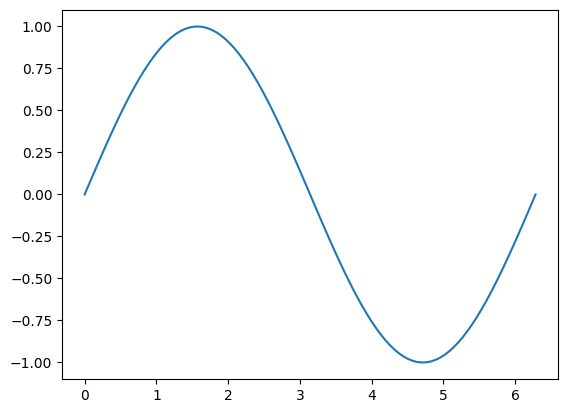

In [34]:
xs = np.linspace(0, 2 * np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()

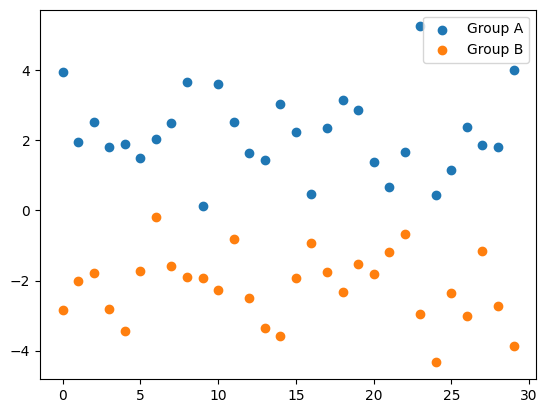

In [40]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.scatter(range(30), group_a, color="C0", label="Group A")
plt.scatter(range(30), group_b, color="C1", label="Group B")

plt.legend()
plt.show()

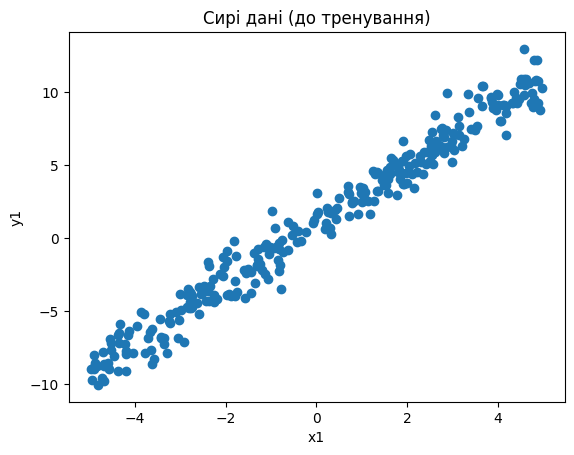

In [43]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

plt.scatter(x1.numpy(), y1.numpy())

plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")

plt.show()

In [44]:
indices = torch.randperm(TASK1_N)
x1 = x1[indices]
y1 = y1[indices]

train_size = int(0.70 * TASK1_N)
val_size = int(0.15 * TASK1_N)

x_train1 = x1[:train_size]
y_train1 = y1[:train_size]

x_val1 = x1[train_size:train_size + val_size]
y_val1 = y1[train_size:train_size + val_size]

x_test1 = x1[train_size + val_size:]
y_test1 = y1[train_size + val_size:]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")

train/val/test: 210/45/45


In [45]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)
snapshots = []

for epoch in range(100):
    optimizer.zero_grad()
    y_pred = task1_model(x_train1)
    loss = loss_fn(y_pred, y_train1)
    loss.backward()
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=48.967857  w=1.6691 (true 2.0)  b=0.9790 (true 1.0)
epoch   30  loss=0.916320  w=2.0153 (true 2.0)  b=0.9905 (true 1.0)
epoch   60  loss=0.916320  w=2.0153 (true 2.0)  b=0.9909 (true 1.0)
epoch   90  loss=0.916320  w=2.0153 (true 2.0)  b=0.9909 (true 1.0)
epoch   99  loss=0.916320  w=2.0153 (true 2.0)  b=0.9909 (true 1.0)


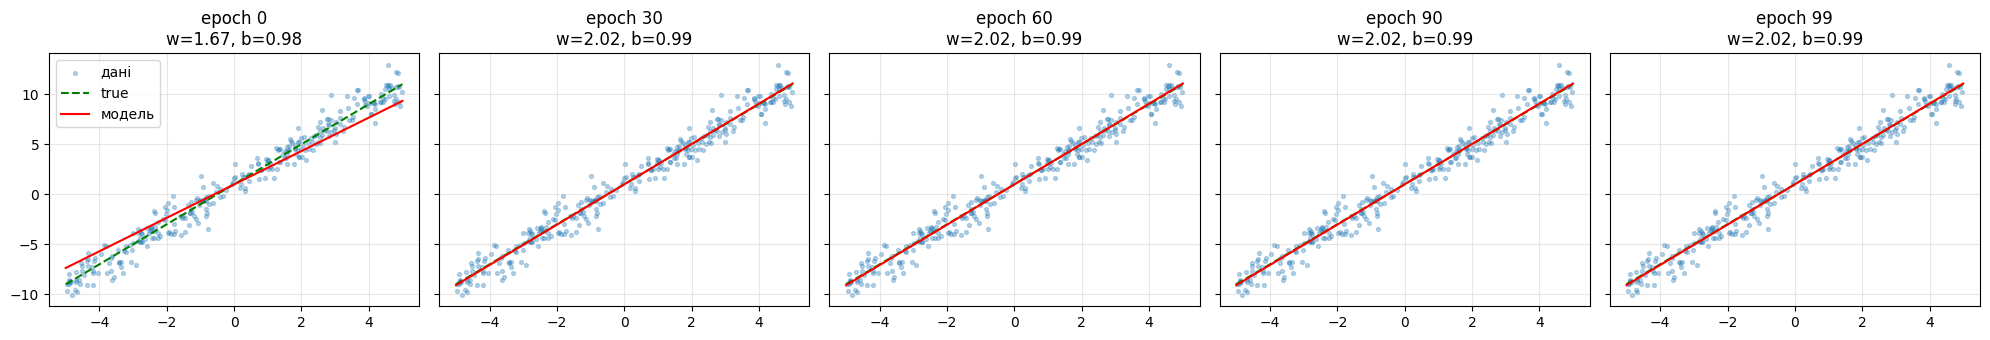

In [46]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


In [ ]:
# досліджується залежність рівня щастя людини від її місячного доходу
# x - місячний дохід у тисячах гривень
# y — умовний індекс щастя від 0 до 100
# для моделювання використаємо лінійну залежність:
# y = 0.8x + 30 + ε
# де w = 0.8, b = 30, а ε — випадковий шум
# припускаємо(та точно), що зі збільшенням доходу
# рівень щастя в середньому зростає. Випадковий шум відображає вплив інших
# факторів, які також можуть впливати на рівень щастя (заміна зчеплення в машині...)

train/val/test: 210/45/45
Epoch   0, loss = 1118.6096
Epoch  40, loss = 155.3353
Epoch  80, loss = 155.0117
Epoch 120, loss = 154.6889
Epoch 160, loss = 154.3670
Epoch 199, loss = 154.0538
Test MSE: 197.3972
Learned w: 1.3363
Learned b: 0.7700


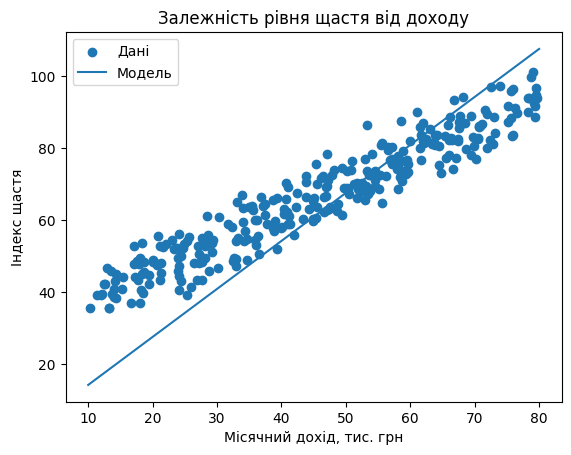

In [47]:
TRUE_W = 0.8
TRUE_B = 30.0
N = 300


def generate_data(n=300):
    income = torch.empty(n, 1).uniform_(10, 80)
    noise = torch.randn(n, 1) * 5
    happiness = TRUE_W * income + TRUE_B + noise
    return income, happiness


def save_to_csv(x, y, filename="income_happiness.csv"):
    df = pd.DataFrame({"income_thousands_uah": x.squeeze().numpy(), "happiness_index": y.squeeze().numpy()})
    df.to_csv(filename, index=False)


def split_data(x, y):
    indices = torch.randperm(len(x))
    x = x[indices]
    y = y[indices]
    train_size = int(0.70 * len(x))
    val_size = int(0.15 * len(x))
    x_train = x[:train_size]
    y_train = y[:train_size]
    x_val = x[train_size:train_size + val_size]
    y_val = y[train_size:train_size + val_size]
    x_test = x[train_size + val_size:]
    y_test = y[train_size + val_size:]

    return x_train, y_train, x_val, y_val, x_test, y_test


def train_model(x_train, y_train, epochs=200, lr=0.0001):
    model = torch.nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model(x_train)
        loss = loss_fn(y_pred, y_train)
        loss.backward()
        optimizer.step()

        if epoch % 40 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch:3d}, loss = {loss.item():.4f}")

    return model


def evaluate_model(model, x_test, y_test):
    loss_fn = torch.nn.MSELoss()

    with torch.no_grad():
        y_pred = model(x_test)
        test_loss = loss_fn(y_pred, y_test)

    print(f"Test MSE: {test_loss.item():.4f}")
    print(f"Learned w: {model.weight.item():.4f}")
    print(f"Learned b: {model.bias.item():.4f}")


def plot_results(model, x, y):
    with torch.no_grad():
        x_line = torch.linspace(10, 80, 100).unsqueeze(1)
        y_line = model(x_line)

    plt.scatter(x.numpy(), y.numpy(), label="Дані")
    plt.plot(x_line.numpy(), y_line.numpy(), label="Модель")

    plt.xlabel("Місячний дохід, тис. грн")
    plt.ylabel("Індекс щастя")
    plt.title("Залежність рівня щастя від доходу")
    plt.legend()
    plt.show()

x, y = generate_data(N)
save_to_csv(x, y)
x_train, y_train, x_val, y_val, x_test, y_test = split_data(x, y)
print(f"train/val/test: " f"{len(x_train)}/{len(x_val)}/{len(x_test)}")
model = train_model(x_train, y_train)
evaluate_model(model, x_test, y_test)
plot_results(model, x, y)

In [51]:
drive.mount('/content/drive')
torch.save(model.state_dict(), '/content/drive/MyDrive/model.pt')
print("Модель збережено")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Модель збережено


In [52]:
path = '/content/drive/MyDrive/model.pt'

print("Файл існує:", os.path.exists(path))
print("Розмір:", os.path.getsize(path), "байт")

Файл існує: True
Розмір: 1877 байт


In [53]:
!pip install -q gradio
import gradio as gr
import torch

In [54]:
loaded_model = torch.nn.Linear(1, 1)
loaded_model.load_state_dict(torch.load('/content/drive/MyDrive/model.pt'))
loaded_model.eval()
print("Модель завантажена")

Модель завантажена


In [56]:
def predict_happiness(income):
    x = torch.tensor([[float(income)]], dtype=torch.float32)

    with torch.no_grad():
        prediction = loaded_model(x)

    return round(prediction.item(), 2)

In [57]:
app = gr.Interface(
    fn=predict_happiness,
    inputs=gr.Number(label="Місячний дохід, тис. грн"),
    outputs=gr.Number(label="Прогнозований індекс щастя"),
    title="Дохід та рівень щастя",
    description="Введіть місячний дохід у тисячах гривень"
)

app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://32d87605e79635de22.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
